# Field tracing: rays and waves in one chain

Field tracing (Wyrowski and Kuhn, *Introduction to field tracing*, J. Mod.
Opt. 58, 449–466, 2011) generalizes ray tracing: a harmonic field, not a
ray bundle, goes through the system, and every part of the system is
modelled with the technique that suits it. In the convective
single-neighbour approximation (one source, every component lit by its
predecessor, no multiple reflections) the output is the product

$$V_\mathrm{out} = P_{J,J-1}\,C_{J-1}\,P_{J-1,J-2}\cdots C_2\,P_{2,1}\,V_\mathrm{source}$$

of free-space operators $P$ and component operators $C$.
`pyoptics.fieldtrace` writes this product as a list:

```python
chain = ft.Chain([ft.ThinLens(100.0), ft.Propagate(100.0), ft.Detector("focus")])
result = chain.run(source)
```

Each `Propagate` picks its operator (spectrum of plane waves, Fresnel,
single-FT Fresnel, far field, geometrical optics) from 1D cuts of the field,
the way the paper proposes, and the field keeps its quadratic phase
analytic, so curved wavefronts cost no samples. Polarization is scalar
while the field is globally polarized and becomes vectorial when a
component depolarizes it (`polarization="auto"`).

This notebook shows

1. the automatic operator choice on the cases of the paper,
2. a ball lens: rays through the glass, waves into the focus
   (`Chain.from_system`), checked against the exact solution of the
   Helmholtz equation for a sphere,
3. a Mach-Zehnder interferometer with a small defect on a lens, after the
   LightTrans use case
   [USC.0464](https://www.lighttrans.com/use-cases/application/mach-zehnder-interferometer-with-small-obstruction.html):
   parallel arms, a Babinet "virtual stop" on its own small grid, checked
   against one brute-force simulation on a fine grid.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from scipy.special import erf, j0

from pyoptics import fieldtrace as ft
from pyoptics.raytrace import System, Surface
from pyoptics.analytical import sphere_field
from pyoptics.propagators import rayleigh_sommerfeld_I_TF

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()

## 1. Which operator? The cases of the paper

The paper's section 3.3 decides between operators by their error against
the rigorous spectrum of plane waves (SPW) and their effort (the samples
they need). `estimate_propagation` does that on the x and y cuts of the
field: every candidate is refined until its result stops changing, its
converged number of samples is the effort, its deviation from the
converged SPW result the error; the cheapest candidate within the
tolerance wins. Three of the paper's cases, at 633 nm (lengths in mm):

* a circular aperture of 50 µm radius (smooth edge) over 1 and 10 mm:
  near field, SPW or Fresnel;
* a 5 µm aperture over 10 mm: far field (SPW would need a huge window);
* a converging spherical wave (R = −100 mm) behind a 10 mm aperture,
  50 mm towards the focus: SPW with the curvature analytic stays cheap,
  and geometrical optics is within the tolerance.

In [2]:
wl = 632.8e-6
def aperture(radius, R=np.inf, order=10, N=64):
    # super-Gaussian aperture of the given radius on a window of 1.25 radii
    x = np.linspace(-1.25*radius, 1.25*radius, N)
    X, Y = np.meshgrid(x, x)
    alpha = 0.0 if np.isinf(R) else np.pi/(wl*R)
    u = np.exp(-(np.hypot(X, Y)/radius)**order)
    return ft.Field(u, x, x, wl, alpha=(alpha, alpha))

rows = [("50 µm aperture, z = 1 mm", aperture(0.05), 1.0),
        ("50 µm aperture, z = 10 mm", aperture(0.05), 10.0),
        ("5 µm aperture, z = 10 mm", aperture(0.005), 10.0),
        ("10 mm sphere R = -100, z = 50", aperture(5.0, R=-100.0, order=20), 50.0)]
print("{:30s} {:11s}  ".format("case", "choice") + "  ".join("{:>17s}".format(m) for m in ft.METHODS))
for name, f, z in rows:
    choice, t = ft.estimate_propagation(f, z)
    cells = []
    for m in ft.METHODS:
        e, n = t[m]["error"], t[m]["effort"]
        cells.append("{:>17s}".format("—" if not np.isfinite(e) else "{:.0e} / {:.0f}".format(e, n)))
    print("{:30s} {:11s}  ".format(name, choice) + "  ".join(cells))
print("\n(error / effort = samples N_x N_y; tolerance 1e-2)")

case                           choice                     spw            fresnel         fresnel_ft           farfield          geometric
50 µm aperture, z = 1 mm       spw              0e+00 / 16384      6e-05 / 16384      6e-04 / 16384       1e+00 / 4096      2e-01 / 16129
50 µm aperture, z = 10 mm      fresnel_ft       0e+00 / 16384      5e-04 / 16384       1e-03 / 4096       5e-01 / 4096      4e-01 / 16129


5 µm aperture, z = 10 mm       farfield     0e+00 / 260176900      3e-01 / 16384       3e-01 / 4096   5e-03 / 16777216      1e+00 / 16129
10 mm sphere R = -100, z = 50  spw               0e+00 / 9604       1e-01 / 9604       1e-01 / 4096       1e+00 / 4096      7e-03 / 16129

(error / effort = samples N_x N_y; tolerance 1e-2)


The choices agree with the paper: SPW for the near field; at 10 mm the
single-FT Fresnel operator, which samples the output independently of the
input and needs half the samples; the far-field operator for the strongly
diverging 5 µm beam (SPW does not even converge within 16k samples per
axis, so its errors are estimates there); and SPW on about 100 samples for
the spherical wave, whose curvature is analytic. Geometrical optics would
also do for the sphere, at an error of 7·10⁻³.

## 2. A ball lens: rays through the glass, waves into the focus

A glass sphere (radius a = 50 µm, n = 1.5) in a flat-top beam of 50 µm
diameter at λ = 0.5 µm focuses with strong spherical aberration about
25 µm behind its back surface. Inside the sphere the field is smooth
and the surfaces are large compared with the wavelength: geometrical
optics (local plane waves, Fresnel coefficients at both surfaces, the
energy law of ray tubes) is accurate there. Near the focus it is not: the
rays form a caustic. `Chain.from_system(system, gap=...)` therefore traces
rays only to a plane `gap` behind the last surface (`Trace`) and hands
over to a wave optical `Propagate` with an automatically chosen
operator.

The reference is the exact solution of the scalar Helmholtz equation for
a sphere (`analytical.sphere_field`, a series of spherical harmonics for
every plane wave cone of the incident beam). Units here are µm.

In [3]:
wl_b, a, n_b, w_b = 0.5, 50.0, 1.5, 25.0
flat = lambda r: np.exp(-(r/w_b)**6)                 # smooth flat top
x = np.linspace(-45, 45, 181)
X, Y = np.meshgrid(x, x)
src = ft.Field(flat(np.hypot(X, Y)), x, x, wl_b)
# the beam is defined in the plane of the sphere's centre: carry it back
# to the front vertex plane (z = -a) with the rigorous operator
front = ft.Chain([ft.Propagate(-a, method="spw")]).run(src).field

d = 25.0                                             # behind the back surface
ball = System([Surface(R=a, thickness=2*a, n_after=n_b, semi_diameter=0.999*a),
               Surface(R=-a, thickness=d, n_after=1.0, semi_diameter=0.999*a)], 0, wl_b)
x_focus = np.linspace(-10, 10, 201)
chain = ft.Chain.from_system(ball, gap=0.5) + [ft.Detector("focus", x=x_focus, y=x_focus)]
t0 = time.time()
res = chain.run(front)
print(res.report())
print("{:.1f} s".format(time.time() - t0))

  #  step                         method              error     samples pol.          ms  notes
  0  trace 2 surfaces             geometric (ray                181x181 scalar     347.4  
  1  propagate 24.5               spw               0.0e+00   4611x4611 scalar   15355.0  SPW reference not converged: errors are estimates
                                  candidates (error/effort): spw 0.0e+00/104019601, fresnel 5.2e-01/104019601, fresnel_ft 2.2e-01/32761, farfield 1.3e+00/33547264, geometric inf/inf
  2  detector 'focus'             detector                    4611x4611 scalar   12528.2  E_z carries 1.7e-02 of |E|^2: included
28.2 s


The trace takes well under a second. Into the focus, through the caustic
of the strongly aberrated sphere, only SPW meets the tolerance, on a large
grid; even its reference is not fully converged at the largest grid the
estimate tries. The detector looks at 20 × 20 µm around the focus. The
comparison along a radius of the focal plane:

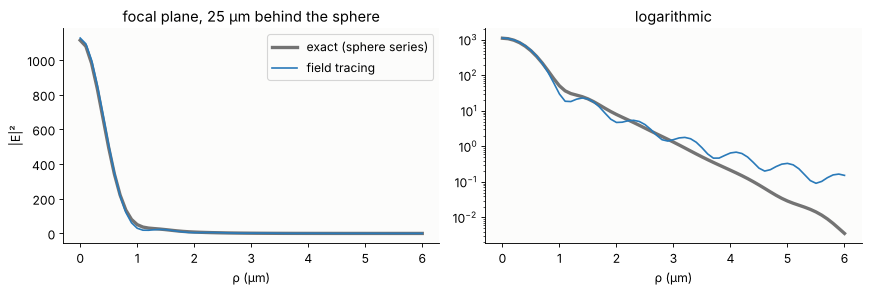

peak: field tracing 1127, exact 1115


In [4]:
# exact: the incident flat top as a sum of plane wave cones (Hankel transform)
r_q = np.linspace(0, 3*w_b, 3001)
k_rho = (np.arange(800) + 0.5)*0.004
A = (flat(r_q)*r_q) @ j0(np.outer(r_q, k_rho))*(r_q[1] - r_q[0])
rho = np.linspace(0, 6, 61)
u_exact = sphere_field(rho, a + d, a, n_b, wl_b, k_rho=k_rho, amplitudes=A*k_rho*0.004)

out = res["focus"].field
cut = out.resample(rho, np.array([-0.05, 0.0, 0.05]))
I_ft = np.abs(cut.E()[0][1])**2 + np.abs(cut.E()[1][1])**2

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(rho, np.abs(u_exact)**2, color=GREY, lw=3, label="exact (sphere series)")
ax[0].plot(rho, I_ft, color=BLUE, lw=1.5, label="field tracing")
ax[0].set_xlabel("ρ (µm)"); ax[0].set_ylabel("|E|²"); ax[0].legend()
ax[0].set_title("focal plane, {:.0f} µm behind the sphere".format(d))
ax[1].semilogy(rho, np.abs(u_exact)**2, color=GREY, lw=3)
ax[1].semilogy(rho, I_ft, color=BLUE, lw=1.5)
ax[1].set_xlabel("ρ (µm)"); ax[1].set_title("logarithmic")
plt.tight_layout(); plt.show()
print("peak: field tracing {:.0f}, exact {:.0f}".format(I_ft[0], np.abs(u_exact[0])**2))

Field tracing reproduces the aberrated focus: the peak within about 1 %,
the first ring and the shoulder within a few per cent. The remaining
differences are of the order of the tolerance (10⁻² of the peak) and come
from the geometrical optics part: rays carry no edge diffraction from the
rim of the beam and miss the weak wave reflected inside the sphere.

The trace is vectorial. An x polarized beam leaves a strongly curved
surface with a cross polarized part in four lobes (the s and p Fresnel
coefficients differ off the planes of incidence through x and y). In
`"auto"` mode the chain checks that share and keeps the field scalar
when it is below the tolerance:

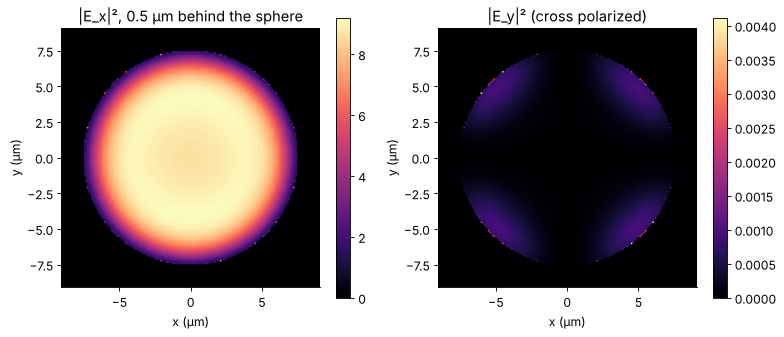

cross polarized share: 3.3e-05; power transmitted: 0.922 (two Fresnel losses: 0.922)


In [5]:
behind = ft.Chain([ft.Trace(System([Surface(R=a, thickness=2*a, n_after=n_b, semi_diameter=0.999*a),
                                    Surface(R=-a, thickness=0.5, n_after=1.0, semi_diameter=0.999*a)],
                                   0, wl_b))]).run(front, polarization="vector").field
Ex, Ey = behind.E()
ext = [behind.x[0], behind.x[-1], behind._y[0], behind._y[-1]]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
im = ax[0].imshow(np.abs(Ex)**2, extent=ext, origin="lower", cmap="magma")
ax[0].set_title("|E_x|², 0.5 µm behind the sphere"); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(np.abs(Ey)**2, extent=ext, origin="lower", cmap="magma")
ax[1].set_title("|E_y|² (cross polarized)"); plt.colorbar(im, ax=ax[1])
for axx in ax: axx.set_xlabel("x (µm)"); axx.set_ylabel("y (µm)")
plt.tight_layout(); plt.show()
print("cross polarized share: {:.1e}; power transmitted: {:.3f} (two Fresnel losses: {:.3f})".format(
    np.sum(np.abs(Ey)**2)/np.sum(np.abs(Ex)**2 + np.abs(Ey)**2), behind.power()/front.power(),
    (1 - ((n_b - 1)/(n_b + 1))**2)**2))

## 3. A Mach-Zehnder interferometer with a small obstruction

After the LightTrans use case
[USC.0464](https://www.lighttrans.com/use-cases/application/mach-zehnder-interferometer-with-small-obstruction.html):
a plane wave of 8 × 8 mm at 800 nm is split into a reference arm with a
2 mm plate and a test arm with a plano-convex lens (R = 1 m, 2 mm centre
thickness) that carries a small defect of 50–300 µm. The arms are
recombined and an irradiance detector looks at the interferogram. The
use case does not give the distances; we take 50 mm from the splitter to
the elements, 50 mm on to the combiner and 50 mm to the camera. The
source has smooth edges (0.1 mm erf), as the plane wave sources of
VirtualLab do.

What makes this hard for a single grid is the mix of scales: the 8 mm
beam is smooth, but the defect is tiny and diffracts strongly. Babinet's
principle splits the field behind the defect into two parts,

$$E\,(1 - M) = E \;-\; E\,M,$$

$M$ the indicator of the defect: the unobstructed beam, and a small
field of opposite sign that lives only on the defect (VirtualLab's
"virtual stop", a second source of opposite phase). `ft.Obstruction`
puts the second part on its own small grid; from then on the chain
carries a `FieldSum`, and every part gets its own grid and its own
operator. `ft.Parallel` holds the two arms the same way. The parts are
added coherently only at the detector.

The plate and the lens are traced (`Trace`) through real surfaces with
Fresnel losses. The weights 0.5 are the two 50/50 splitters
($1/\sqrt2$ each) of the bright output port.

In [6]:
wl_m, n_g, R_l, T_p, L = 0.0008, 1.5, 1000.0, 2.0, 50.0       # mm
edge = lambda u: 0.5*(1 - erf((np.abs(u) - 4.0)/0.1))
square = lambda X, Y: edge(X)*edge(Y)

x = np.linspace(-5, 5, 513)
X, Y = np.meshgrid(x, x)
source = ft.Field(square(X, Y), x, x, wl_m)
plate = System([Surface(thickness=T_p, n_after=n_g, semi_diameter=6.0),
                Surface(thickness=0.0, n_after=1.0, semi_diameter=6.0)], 0, wl_m)
lens = System([Surface(R=R_l, thickness=T_p, n_after=n_g, semi_diameter=6.0),
               Surface(thickness=0.0, n_after=1.0, semi_diameter=6.0)], 0, wl_m)
x_cam = np.linspace(-5, 5, 1001)
center = (1.0, 0.5)

def interferometer(radius):
    return ft.Chain([
        ft.Parallel([ft.Propagate(L), ft.Trace(plate), ft.Propagate(L)],
                    [ft.Propagate(L), ft.Trace(lens),
                     ft.Obstruction(radius=radius, center=center), ft.Propagate(L)],
                    weights=(0.5, 0.5)),
        ft.Propagate(L),
        ft.Detector("camera", x=x_cam, y=x_cam)])

t0 = time.time()
res = interferometer(0.1).run(source)
t_ft = time.time() - t0
print(res.report())
print("field tracing: {:.1f} s".format(t_ft))

  #  step                         method              error     samples pol.          ms  notes
0.1.0  propagate 50                 spw               0.0e+00     513x513 scalar     441.5  
                                  candidates (error/effort): spw 0.0e+00/263169, fresnel 5.0e-08/263169, fresnel_ft 1.8e-06/263169, farfield 2.2e+00/263169, geometric 3.0e-02/263169
0.1.1  trace 2 surfaces             geometric (ray                513x513 scalar     462.3  
0.1.2  propagate 50                 spw               0.0e+00     513x513 scalar     387.2  
                                  candidates (error/effort): spw 0.0e+00/263169, fresnel 2.8e-06/263169, fresnel_ft 7.2e-05/263169, farfield 2.2e+00/263169, geometric 1.9e-02/263169
0.2.0  propagate 50                 spw               0.0e+00     513x513 scalar     366.1  
                                  candidates (error/effort): spw 0.0e+00/263169, fresnel 5.0e-08/263169, fresnel_ft 1.8e-06/263169, farfield 2.2e+00/263169, geometric 3

The report shows the structure: the arms (steps 0.1.x and 0.2.x), and
the Babinet part of the 200 µm defect on a grid of 31 × 31 samples, which
the propagation spreads over the 10 mm of the beam on about 60 × 60
samples (SPW in the far branch of the semi-analytical transform, or the
single-FT Fresnel operator, whichever is cheaper), while the two beams
stay on 513 × 513. Each part's error budget is the
tolerance relative to the *whole* field, so the weak Babinet part may be
less accurate by the ratio of the amplitudes (at most three times the
tolerance).

The reference is one brute-force simulation of the same system: the
angular spectrum method on a 4096 × 4096 grid of 12 mm (2.9 µm samples),
the lenses as thin elements with the same Fresnel losses, the defect a
hard disk.

brute force: 9.5 s, field tracing: 5.0 s
relative L2 difference of the interferograms: 9.9e-03


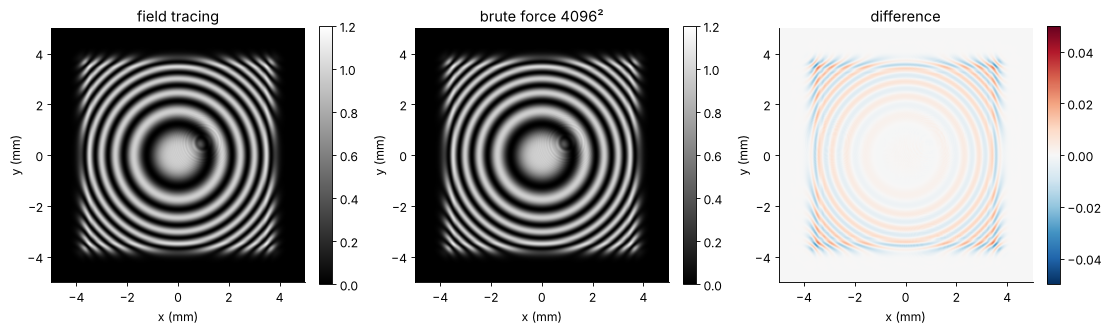

In [7]:
def brute_force(radius, N=4096, half=6.0):
    xb = np.linspace(-half, half, N)
    XB, YB = np.meshgrid(xb, xb)
    k = 2*np.pi/wl_m
    P = lambda u, z: rayleigh_sommerfeld_I_TF(u, xb, xb, z, wl_m)[0]
    t = 1 - ((n_g - 1)/(n_g + 1))**2                 # two surfaces: amplitude t
    u1 = P(square(XB, YB).astype(complex), L)
    ref = P(u1*t*np.exp(1j*k*n_g*T_p), L)
    h = T_p - (R_l - np.sqrt(R_l**2 - XB**2 - YB**2))   # glass thickness of the lens
    defect = ((XB - center[0])**2 + (YB - center[1])**2) > radius**2
    test = P(u1*t*np.exp(1j*k*(n_g*h + (T_p - h)))*defect, L)
    del u1
    u = P(0.5*(ref + test), L)
    pts = np.stack(np.meshgrid(x_cam, x_cam, indexing="ij"), -1)
    return RegularGridInterpolator((xb, xb), np.abs(u)**2)(pts)

t0 = time.time()
I_bf = brute_force(0.1)
t_bf = time.time() - t0
I_ft = res["camera"].irradiance
print("brute force: {:.1f} s, field tracing: {:.1f} s".format(t_bf, t_ft))
print("relative L2 difference of the interferograms: {:.1e}".format(
    np.linalg.norm(I_ft - I_bf)/np.linalg.norm(I_bf)))

ext = [x_cam[0], x_cam[-1]]*2
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
for axx, I, title in zip(ax, (I_ft, I_bf, I_ft - I_bf),
                         ("field tracing", "brute force 4096²", "difference")):
    kw = dict(cmap="RdBu_r", vmin=-0.05, vmax=0.05) if title == "difference" else dict(cmap="gray", vmin=0, vmax=1.2)
    im = axx.imshow(I, extent=ext, origin="lower", **kw)
    axx.set_title(title); axx.set_xlabel("x (mm)"); axx.set_ylabel("y (mm)")
    plt.colorbar(im, ax=axx, fraction=0.046)
plt.tight_layout(); plt.show()

The interferograms agree to about 1 % (L2), the tolerance of the chain,
at less than half the run time of the brute-force grid, which in
addition needs about 2 GB. The field tracing chain does not grow with
the defect: it stays on 31 samples across it whatever its size, while a
single grid must resolve the smallest feature over the whole beam.

Newton's rings come from the lens (focal length R/(n − 1) = 2 m) against
the plane reference; the defect at (1, 0.5) mm throws its diffraction
pattern into them. Defects from 50 to 300 µm:

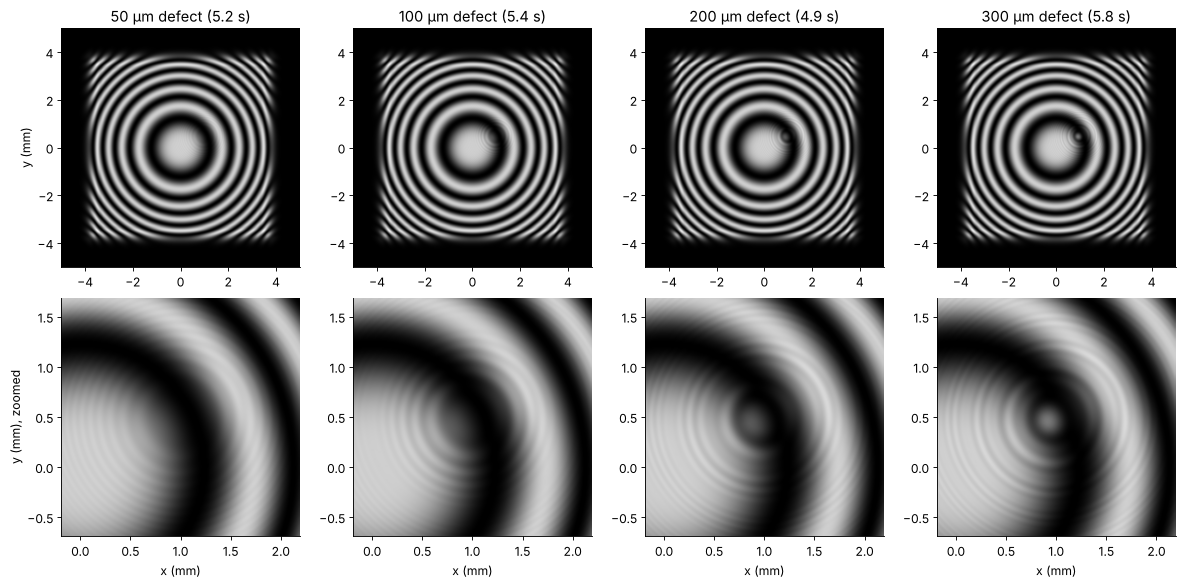

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(15, 7.4))
zoom = (np.abs(x_cam - center[0]) < 1.2)
zoom_y = (np.abs(x_cam - center[1]) < 1.2)
for j, diameter in enumerate((0.05, 0.1, 0.2, 0.3)):
    t0 = time.time()
    r = interferometer(diameter/2).run(source)
    I = r["camera"].irradiance
    ax[0, j].imshow(I, extent=ext, origin="lower", cmap="gray", vmin=0, vmax=1.2)
    ax[0, j].set_title("{:.0f} µm defect ({:.1f} s)".format(diameter*1E3, time.time() - t0))
    ax[1, j].imshow(I[np.ix_(zoom_y, zoom)], origin="lower", cmap="gray", vmin=0, vmax=1.2,
                    extent=[x_cam[zoom][0], x_cam[zoom][-1], x_cam[zoom_y][0], x_cam[zoom_y][-1]])
    ax[1, j].set_xlabel("x (mm)")
ax[0, 0].set_ylabel("y (mm)"); ax[1, 0].set_ylabel("y (mm), zoomed")
plt.tight_layout(); plt.show()

## Summary

* A chain is a list of steps; the free-space operators are chosen per
  step from cuts of the field, as in the paper, and logged with their
  error and effort.
* `Trace(system)` and `Chain.from_system(system, gap=...)` take a field
  through real surfaces with a polarization ray trace and hand over to
  wave optics where diffraction matters; the ball lens focus agrees with
  the exact sphere solution at the 10⁻² level.
* `Parallel` arms and `Obstruction` (Babinet) parts keep fields with very
  different scales on their own grids; the Mach-Zehnder interferogram
  with a 200 µm defect matches a 4096² brute-force grid within 1 %.

In [9]:
print("total run time: {:.0f} s".format(time.time() - t_start))

total run time: 68 s
